## This notebook is ment for the testing of spectral methods

In [113]:
import numpy as np
import matplotlib.pyplot as plt

from linearKdV import spectral_linear_kdv_solver as slKdV

In [114]:
def gaussian(x,a):
    return np.exp(-a*x**2)

In [125]:
L = 2**8
T = 30
dt = 1e-1
D = 8
x_arr = np.linspace(-D,D,L)
u_0 = gaussian(x_arr,1/5**2)*np.cos(10*x_arr)
# u_0 = (np.exp(-((x_arr+10)/3)**2)*np.cos(4*x_arr)
# + 0.7*np.exp(-((x_arr-10)/2)**2)*np.cos(8*x_arr)
# )
u_0_hat = np.fft.fft(u_0)

In [126]:
u_hat = slKdV(u_0_hat, L ,T , dt)

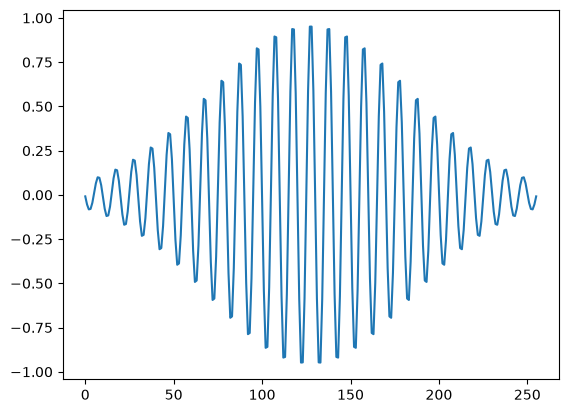

In [127]:
# plt.plot((u_hat).real)
plt.plot(u_0)
plt.show()

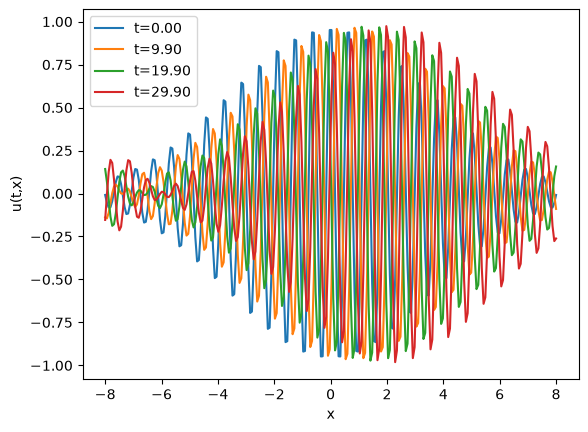

In [128]:
times = np.linspace(0,T/dt -1, 4, dtype = int)
u = np.fft.ifft(u_hat, axis = 1).real

for n in times:
    plt.plot(x_arr,u[n] , label = f"t={n*dt:.2f}")

plt.legend()
plt.xlabel("x")
plt.ylabel("u(t,x)")
plt.show()

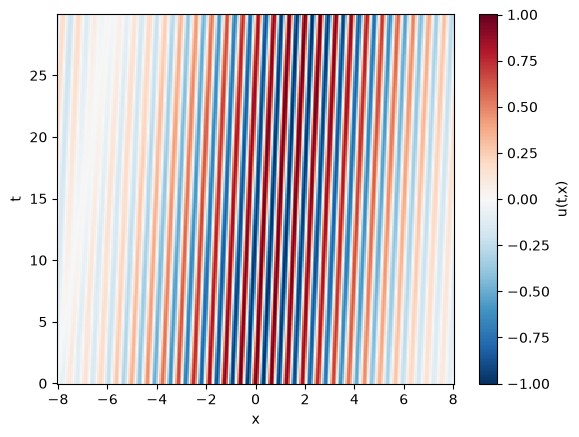

In [129]:
t = np.arange(u.shape[0])*dt
plt.pcolormesh(
    x_arr,
    t,
    u,
    shading = 'auto',
    cmap = 'RdBu_r'
)
plt.xlabel('x')
plt.ylabel('t')
plt.colorbar(label="u(t,x)")
plt.show()